# Loading and preprocessing · Nihal
**Project 24 · Activity Recognition System · Review 2.** Run the cells top to bottom (Jupyter: kernel *har*; Colab: run the setup cell first, it fetches the data and models).

In [1]:
import os, sys, subprocess, pathlib, urllib.request, zipfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("/content/activity-recognition"):
        subprocess.run(["git", "clone", "-q", "https://github.com/rajyyug1132/activity-recognition", "/content/activity-recognition"], check=True)
    os.chdir("/content/activity-recognition")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe", "scikit-learn==1.9.1"], check=True)
    os.makedirs("data/uci", exist_ok=True); os.makedirs("models", exist_ok=True)
    if not os.path.exists("data/uci/UCI HAR Dataset"):
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", "data/uci/har.zip")
        zipfile.ZipFile("data/uci/har.zip").extractall("data/uci")
        zipfile.ZipFile("data/uci/UCI HAR Dataset.zip").extractall("data/uci")
    if not os.path.exists("models/pose_landmarker_full.task"):
        urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task", "models/pose_landmarker_full.task")
    from google.colab import drive
    drive.mount("/content/drive")
    for f in ["cnn_uci.keras", "video_rf.joblib"]:
        if os.path.exists(f"/content/drive/MyDrive/{f}"):
            subprocess.run(["cp", f"/content/drive/MyDrive/{f}", f"models/{f}"], check=True)
elif pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root

sys.path.insert(0, "src")
for f in ["config/config.yaml", "app/demo/uci_test_person_12.csv", "data/uci/UCI HAR Dataset",
          "models/cnn_uci.keras", "models/video_rf.joblib", "models/pose_landmarker_full.task"]:
    print("found  " if os.path.exists(f) else "MISSING", f)

found   config/config.yaml
found   app/demo/uci_test_person_12.csv
found   data/uci/UCI HAR Dataset
found   models/cnn_uci.keras
found   models/video_rf.joblib
found   models/pose_landmarker_full.task


In [2]:
%matplotlib inline
import inspect, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Code, Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(fn):
    """Print a function's source exactly as it is in src/."""
    display(Code(inspect.getsource(fn), language="python"))

cfg = yaml.safe_load(open("config/config.yaml"))
DEMO = "app/demo/uci_test_person_12.csv"
NAMES = {"WALKING": "Walking", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sitting", "STANDING": "Standing", "LAYING": "Lying"}
COLOURS = {"WALKING": "#2bb3a3", "WALKING_DOWNSTAIRS": "#2b3a8f", "WALKING_UPSTAIRS": "#7fb8e6",
           "SITTING": "#e9853a", "STANDING": "#e8c547", "LAYING": "#7a2e6e"}

## 2. Loading and preprocessing · Nihal
**What to say**
- `load_uci` reads UCI HAR's nine signal files into windows of 128 samples × 9 channels, already split by person: 21 training people and 9 test people.
- `to_windows` turns any phone CSV into the same shape: resample to exactly 50 Hz, a median filter and a 20 Hz low-pass filter for noise, a 0.3 Hz low-pass filter to split gravity from body motion, then 128-sample windows overlapping by half.
- `normalize` uses the mean and spread of the training data only, saved in `config/norm_stats.npz`, so nothing from the test people leaks in.

In [3]:
from data_loader import load_uci
show(load_uci)

def load_uci(root) -> dict:
    """Returns X_raw [N,128,9], X_feat [N,561], y [N] (0-5), subject [N] for train and test.

    Shape: {"train": {"X_raw", "X_feat", "y", "subject"}, "test": {...}}.
    `root` is the unzipped "UCI HAR Dataset" folder.
    """
    out = {}
    for split in ("train", "test"):
        out[split] = {
            "X_raw": _raw(root, split),
            "X_feat": np.loadtxt(f"{root}/{split}/X_{split}.txt"),
            "y": np.loadtxt(f"{root}/{split}/y_{split}.txt", dtype=int) - 1,
            "subject": np.loadtxt(f"{root}/{split}/subject_{split}.txt", dtype=int),
        }
    return out

In [4]:
from data_loader import _raw
X_test = _raw("data/uci/UCI HAR Dataset", "test")   # test split only, so this runs in seconds
print(f"test: {X_test.shape[0]:,} windows of {X_test.shape[1]} samples x {X_test.shape[2]} channels, 9 people "
      "(the training split is 7,352 windows from 21 people)")

test: 2,947 windows of 128 samples x 9 channels, 9 people (the training split is 7,352 windows from 21 people)


In [5]:
from preprocess import to_windows, normalize
show(to_windows)

def to_windows(df, cfg) -> np.ndarray:
    """Resample to 50 Hz, filter, cut 128-sample windows at cfg overlap. Returns [N,128,9].

    Input columns: timestamp (s), acc_x/y/z (g, incl. gravity), gyro_x/y/z (rad/s).
    Channel order matches data_loader.SIGNALS: body_acc, body_gyro, total_acc.
    """
    fs, win = cfg["sampling_rate_hz"], cfg["window_samples"]
    step = int(win * (1 - cfg["overlap"]))
    df = df.dropna(subset=["timestamp"] + COLS).sort_values("timestamp")
    df = df.drop_duplicates("timestamp")
    t = df["timestamp"].to_numpy(float)
    grid = np.arange(t[0], t[-1], 1 / fs)
    if len(grid) < win:
        return np.empty((0, win, 9))
    # ponytail: linear interp also fills short gaps; validate_csv rejects long ones
    x = np.stack([np.interp(grid, t, df[c].to_numpy(float)) for c in COLS], axis=1)
    x = medfilt(x, kernel_size=(3, 1))
    x = _lowpass(x, cfg["noise_cutoff_hz"], fs)
    total, gyro = x[:, :3], x[:, 3:]
    body = total - _lowpass(total, cfg["gravity_cutoff_hz"], fs)
    sig = np.concatenate([body, gyro, total], axis=1)          # [T, 9]
    starts = range(0, len(sig) - win + 1, step)
    return np.stack([sig[s:s + win] for s in starts])

sample recording: 6,208 rows at 50 Hz (124 s) -> 95 windows of 128 x 9


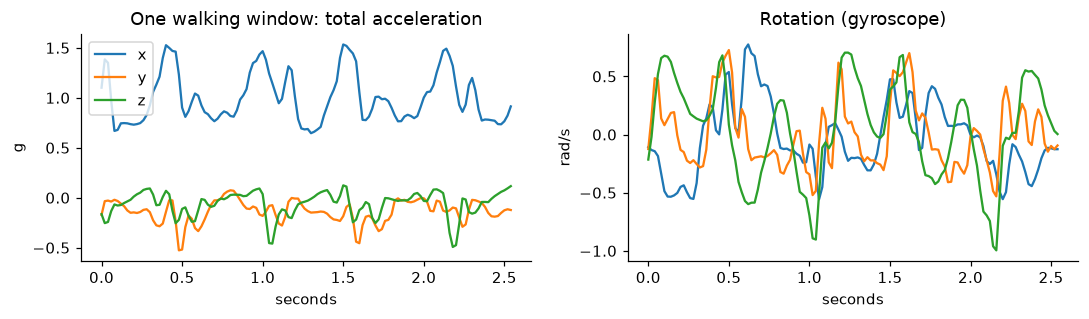

In [6]:
demo = pd.read_csv(DEMO)
X = to_windows(demo, cfg)
print(f"sample recording: {len(demo):,} rows at 50 Hz ({demo.timestamp.iloc[-1]:.0f} s) -> {X.shape[0]} windows of {X.shape[1]} x {X.shape[2]}")
t = np.arange(128) / 50
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for i, axis in enumerate("xyz"):
    ax[0].plot(t, X[3, :, 6 + i], label=axis)   # channels 6-8: total acceleration
    ax[1].plot(t, X[3, :, 3 + i], label=axis)   # channels 3-5: rotation
ax[0].set(title="One walking window: total acceleration", xlabel="seconds", ylabel="g")
ax[1].set(title="Rotation (gyroscope)", xlabel="seconds", ylabel="rad/s")
ax[0].legend(); plt.tight_layout(); plt.show()

In [7]:
show(normalize)
Xn = normalize(X, cfg["norm_stats"])
print(f"before: mean {X.mean():.3f}, std {X.std():.3f}   after: mean {Xn.mean():.3f}, std {Xn.std():.3f}")

def normalize(X, path):
    s = np.load(path)
    return (X - s["mean"]) / s["std"]

before: mean 0.096, std 0.385   after: mean -0.009, std 0.872
